**420-C74-SF - Techniques d'apprentissage automatique - Automne 2026 - Spécialiste en solutions d'intelligence artificielle**<br/>
© 2026 MKL.AI - Tous droits réservés
<br/>
![Atelier - Arbres de décision](static/14-banner.png)
<br/>
**Objectif:** cette séance de travaux pratiques a pour objectif la mise en oeuvre des arbres de régression et de classification. Les jeux de données utilisés seront **Hitters** (Baseball) et **Heart**

In [1]:
%reload_ext autoreload
%autoreload 2
%matplotlib inline

## Exercice 1 - Arbres de régression

### 1-1 Chargement du jeu de données Hitters et exploration sommaire

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="darkgrid", rc={'figure.figsize':(12,6)})

HIT = pd.read_csv('../../data/Hitters.csv', index_col=0)

In [3]:
HIT.head()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
-Andy Allanson,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
-Alan Ashby,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
-Alvin Davis,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
-Andre Dawson,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
-Andres Galarraga,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


In [4]:
HIT.info()

<class 'pandas.DataFrame'>
Index: 322 entries, -Andy Allanson to -Willie Wilson
Data columns (total 20 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   AtBat      322 non-null    int64  
 1   Hits       322 non-null    int64  
 2   HmRun      322 non-null    int64  
 3   Runs       322 non-null    int64  
 4   RBI        322 non-null    int64  
 5   Walks      322 non-null    int64  
 6   Years      322 non-null    int64  
 7   CAtBat     322 non-null    int64  
 8   CHits      322 non-null    int64  
 9   CHmRun     322 non-null    int64  
 10  CRuns      322 non-null    int64  
 11  CRBI       322 non-null    int64  
 12  CWalks     322 non-null    int64  
 13  League     322 non-null    str    
 14  Division   322 non-null    str    
 15  PutOuts    322 non-null    int64  
 16  Assists    322 non-null    int64  
 17  Errors     322 non-null    int64  
 18  Salary     263 non-null    float64
 19  NewLeague  322 non-null    str    
dtypes:

### 1-2 Suppression des observations ayant des valeurs manquantes

In [5]:
# 59 joueurs n'ont pas de salaire (variable réponse manquante)
print(f"Avant: {HIT.shape[0]} observations")
HIT = HIT.dropna()
print(f"Après: {HIT.shape[0]} observations")

Avant: 322 observations
Après: 263 observations


### 1-3 Préparation de la structure de données

In [6]:
# Variables catégorielles (League, Division, NewLeague) => variables indicatrices
X = pd.get_dummies(HIT.drop(['Salary'], axis=1), drop_first=True, dtype=int)
# La distribution du salaire est très asymétrique => on modélise le log du salaire
y = np.log(HIT['Salary'])
X.shape

(263, 19)

### 1-4 Validation croisée Holdout 

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=2020)
print(f'X_train: {X_train.shape[0]} observations')
print(f'X_val: {X_val.shape[0]} observations')

X_train: 184 observations
X_val: 79 observations


### 1-5 Mise en oeuvre de l'arbre de régression

In [8]:
from sklearn.tree import DecisionTreeRegressor

[class sklearn.tree.DecisionTreeRegressor(criterion='mse', splitter='best', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None, random_state=None, max_leaf_nodes=None, min_impurity_decrease=0.0, min_impurity_split=None, presort='deprecated', ccp_alpha=0.0)](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)

In [9]:
# Arbre complet (pas de limite de profondeur, pas d'élagage)
reg_tree = DecisionTreeRegressor(random_state=2020)
reg_tree.fit(X_train, y_train)
print(f"Profondeur: {reg_tree.get_depth()} - Nombre de feuilles: {reg_tree.get_n_leaves()}")

Profondeur: 14 - Nombre de feuilles: 170


### 1-6 Évaluation du modèle

In [10]:
from sklearn.metrics import mean_squared_error, r2_score

In [11]:
y_train_pred = reg_tree.predict(X_train)
y_val_pred = reg_tree.predict(X_val)

In [12]:
print(f'MSE Train = {mean_squared_error(y_train, y_train_pred):.4f} - R2 Train = {r2_score(y_train, y_train_pred):.4f}')
print(f'MSE Val   = {mean_squared_error(y_val, y_val_pred):.4f} - R2 Val   = {r2_score(y_val, y_val_pred):.4f}')

MSE Train = 0.0000 - R2 Train = 1.0000
MSE Val   = 0.3603 - R2 Val   = 0.5317


**Constat :** l'arbre complet (profondeur 14, 170 feuilles pour 184 observations) mémorise le jeu d'entraînement (MSE = 0, R² = 1) mais généralise mal (R² validation ≈ 0,53) : c'est un cas typique de **surapprentissage** (variance élevée).

### 1-7 Visualisation de l'arbre

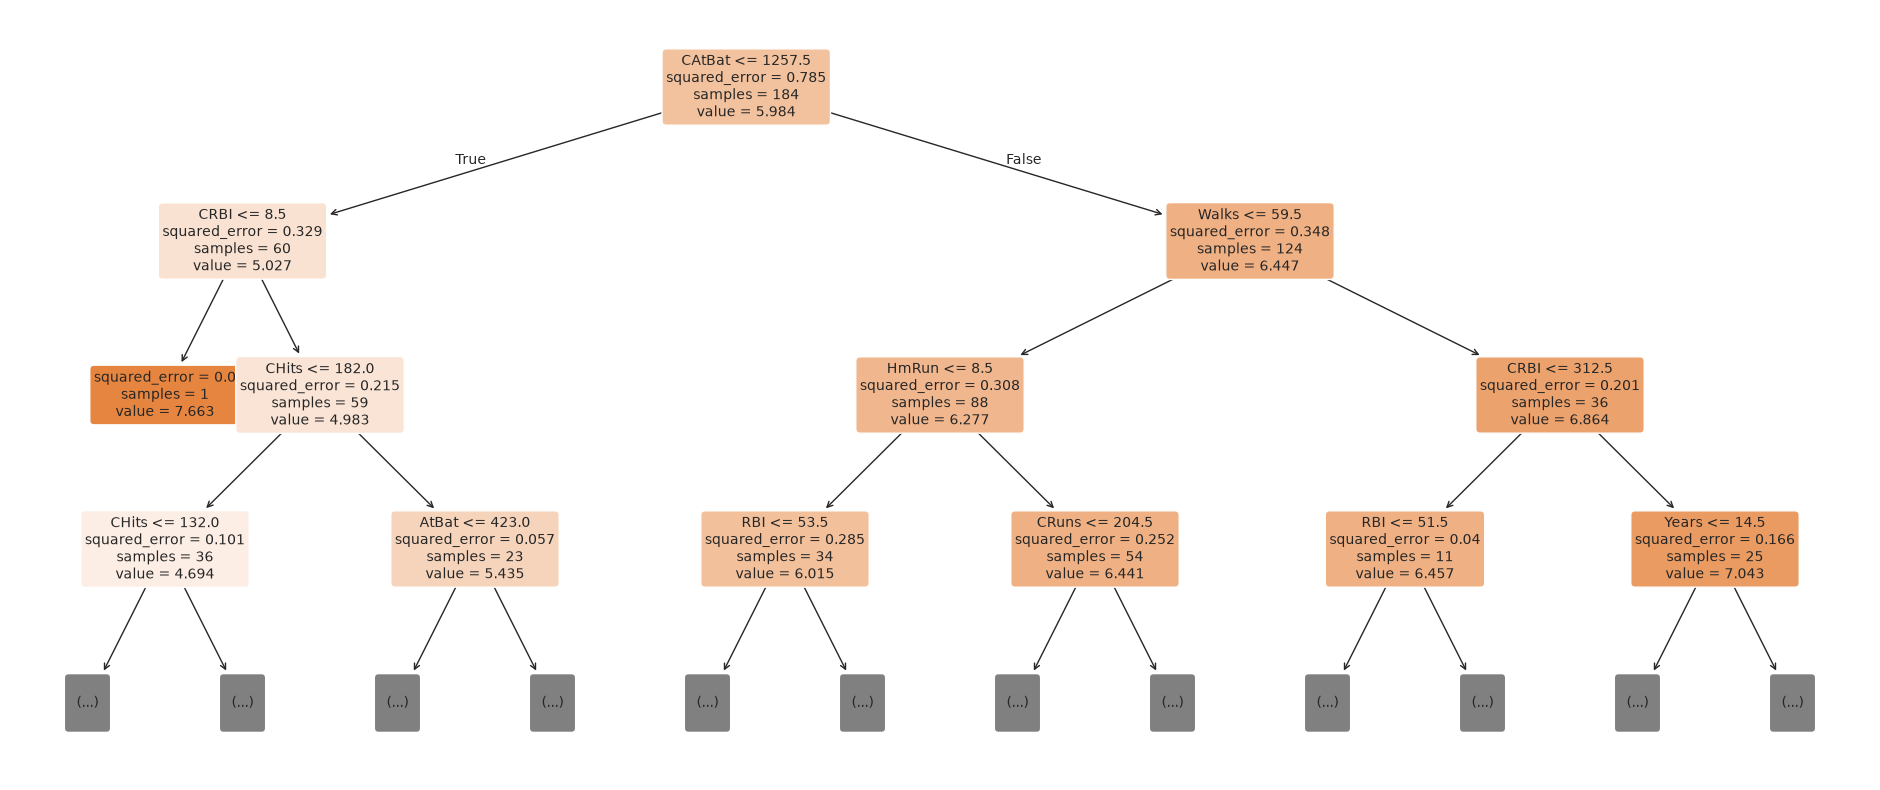

In [15]:
from sklearn.tree import plot_tree

# L'arbre complet est illisible => on n'affiche que les 3 premiers niveaux
plt.figure(figsize=(24,10))
plot_tree(reg_tree, feature_names=X.columns, max_depth=3, filled=True, rounded=True, fontsize=10)
plt.show()

### 1-8 Application de l'élagage et ré-évaluation du modèle

In [16]:
# Chemin d'élagage coût-complexité: valeurs de alpha pour lesquelles l'arbre change
path = reg_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1] # La dernière valeur donne un arbre réduit à la racine

mse_train, mse_val = [], []
for ccp_alpha in ccp_alphas:
    tree = DecisionTreeRegressor(random_state=2020, ccp_alpha=ccp_alpha)
    tree.fit(X_train, y_train)
    mse_train.append(mean_squared_error(y_train, tree.predict(X_train)))
    mse_val.append(mean_squared_error(y_val, tree.predict(X_val)))

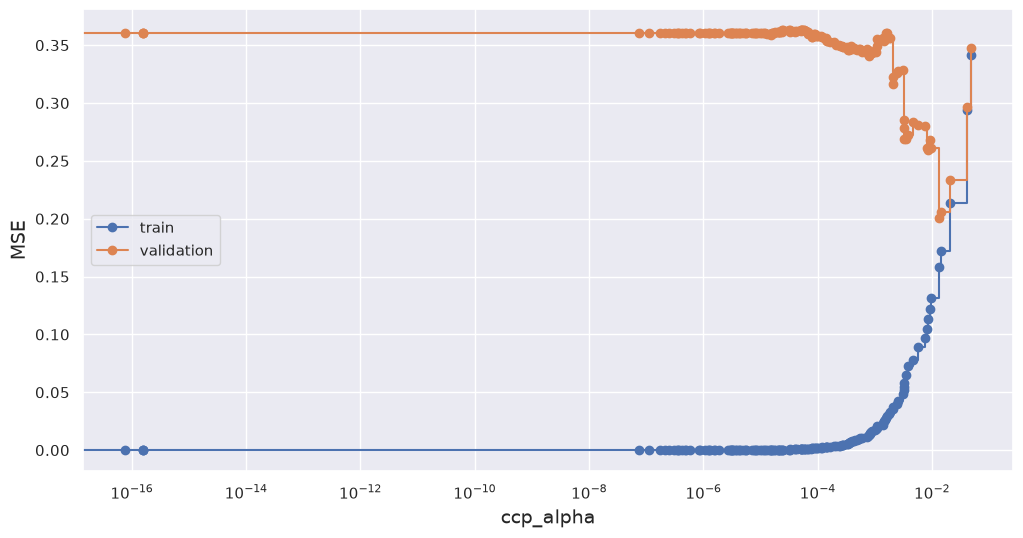

In [17]:
f, ax = plt.subplots(1,1)
ax.plot(ccp_alphas, mse_train, marker='o', drawstyle="steps-post", label="train")
ax.plot(ccp_alphas, mse_val, marker='o', drawstyle="steps-post", label="validation")
ax.set_xscale('log')
ax.set_xlabel('ccp_alpha', fontsize=14)
ax.set_ylabel('MSE', fontsize=14)
ax.legend()

In [18]:
best_alpha = ccp_alphas[np.argmin(mse_val)]
print(f"Meilleur alpha = {best_alpha:.4f}")

reg_tree_pruned = DecisionTreeRegressor(random_state=2020, ccp_alpha=best_alpha)
reg_tree_pruned.fit(X_train, y_train)
print(f"Profondeur: {reg_tree_pruned.get_depth()} - Nombre de feuilles: {reg_tree_pruned.get_n_leaves()}")

y_train_pred = reg_tree_pruned.predict(X_train)
y_val_pred = reg_tree_pruned.predict(X_val)
print(f'MSE Train = {mean_squared_error(y_train, y_train_pred):.4f} - R2 Train = {r2_score(y_train, y_train_pred):.4f}')
print(f'MSE Val   = {mean_squared_error(y_val, y_val_pred):.4f} - R2 Val   = {r2_score(y_val, y_val_pred):.4f}')

Meilleur alpha = 0.0131
Profondeur: 4 - Nombre de feuilles: 8
MSE Train = 0.1580 - R2 Train = 0.7986
MSE Val   = 0.2002 - R2 Val   = 0.7397


**Constat :** l'élagage par coût-complexité (`ccp_alpha`) réduit l'arbre à 8 feuilles. L'erreur d'entraînement augmente, mais l'erreur de validation diminue fortement (MSE 0,36 → 0,20, R² 0,53 → 0,74) : l'arbre élagué offre un bien meilleur compromis biais-variance.

### 1-9 Visualisation de l'arbre élagué

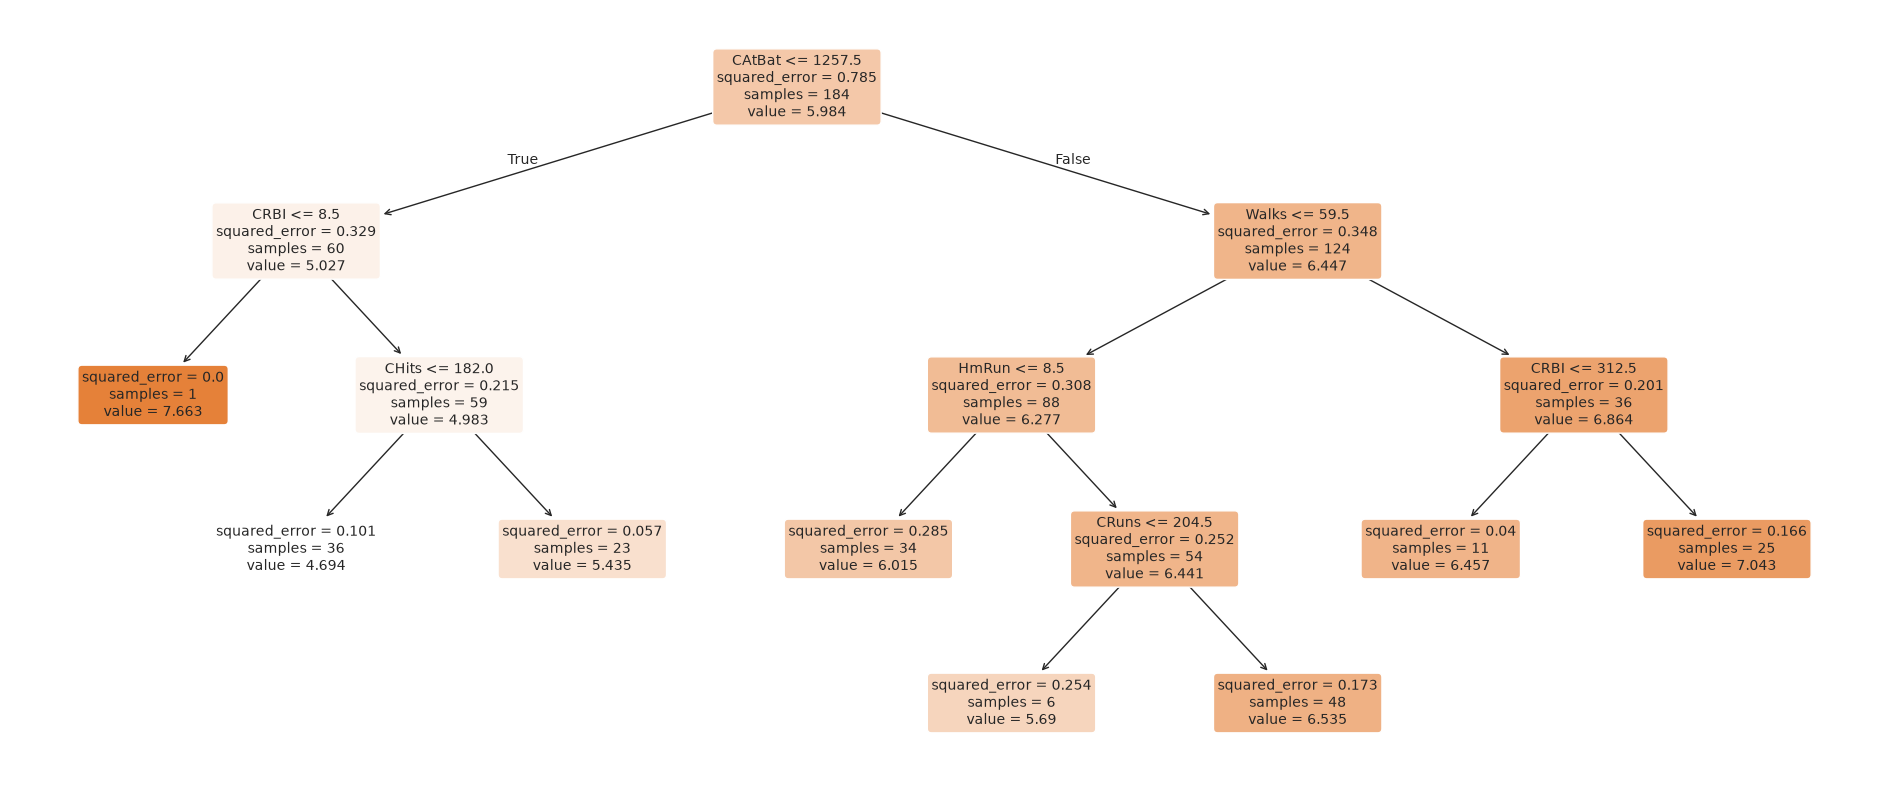

In [19]:
plt.figure(figsize=(24,10))
plot_tree(reg_tree_pruned, feature_names=X.columns, filled=True, rounded=True, fontsize=10)
plt.show()

## Exercice 2 - Arbres de classification

### 2-1 Chargement et préparation du jeu de données Heart

In [20]:
HRT = pd.read_csv('../../data/Heart.csv', index_col=0)
HRT = HRT.dropna()
HRT.head()

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


### 2-2 Préparation de la structure de données

In [21]:
# Variables catégorielles (ChestPain, Thal) => variables indicatrices
X = pd.get_dummies(HRT.drop(['AHD'], axis=1), drop_first=True, dtype=int)
y = HRT['AHD'].map({'No': 0, 'Yes': 1})
X.shape

(297, 16)

### 2-3 Validation croisée Holdout 

In [22]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=2020)
print(f'X_train: {X_train.shape[0]} observations')
print(f'X_val: {X_val.shape[0]} observations')

X_train: 207 observations
X_val: 90 observations


### 2-4 Mise en oeuvre de l'arbre de classification

In [23]:
from sklearn.tree import DecisionTreeClassifier

[class sklearn.tree.DecisionTreeClassifier(criterion='gini', splitter='best', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None, random_state=None, max_leaf_nodes=None, min_impurity_decrease=0.0, min_impurity_split=None, class_weight=None, presort='deprecated', ccp_alpha=0.0)](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)

In [24]:
clf_tree = DecisionTreeClassifier(random_state=2020)
clf_tree.fit(X_train, y_train)
print(f"Profondeur: {clf_tree.get_depth()} - Nombre de feuilles: {clf_tree.get_n_leaves()}")

Profondeur: 8 - Nombre de feuilles: 38


### 2-5 Évaluation du modèle

In [27]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

In [28]:
y_train_pred = clf_tree.predict(X_train)
y_val_pred = clf_tree.predict(X_val)
y_train_pred_proba = clf_tree.predict_proba(X_train)[:,1]
y_val_pred_proba = clf_tree.predict_proba(X_val)[:,1]

In [29]:
print(f'Accuracy Train = {accuracy_score(y_train, y_train_pred):.4f}')
print(f'Accuracy Val   = {accuracy_score(y_val, y_val_pred):.4f}')

Accuracy Train = 1.0000
Accuracy Val   = 0.7000


In [ ]:
print(confusion_matrix(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred, target_names=['No', 'Yes']))

In [ ]:
# L'arbre complet a des feuilles pures => probabilités 0 ou 1 => AUC train = 1
print(f'AUC Train = {roc_auc_score(y_train, y_train_pred_proba):.4f}')
print(f'AUC Val   = {roc_auc_score(y_val, y_val_pred_proba):.4f}')

**Constat :** comme en régression, l'arbre complet surajuste : accuracy et AUC de 100 % en entraînement, contre ≈ 70 % en validation.

### 2-6 Application de l'élagage et ré-évaluation du modèle

In [30]:
path = clf_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1] # La dernière valeur donne un arbre réduit à la racine

acc_train, acc_val = [], []
for ccp_alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=2020, ccp_alpha=ccp_alpha)
    tree.fit(X_train, y_train)
    acc_train.append(accuracy_score(y_train, tree.predict(X_train)))
    acc_val.append(accuracy_score(y_val, tree.predict(X_val)))

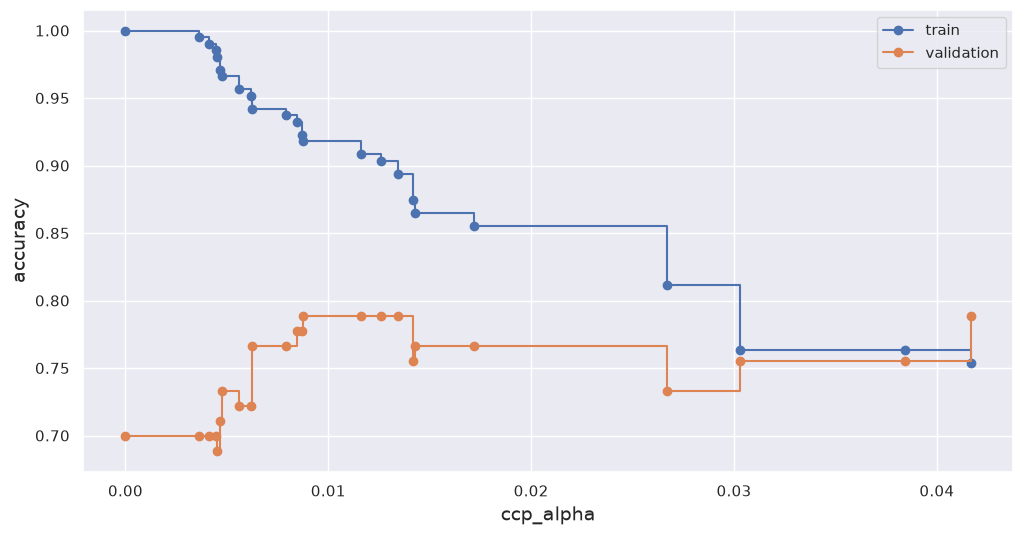

In [31]:
f, ax = plt.subplots(1,1)
ax.plot(ccp_alphas, acc_train, marker='o', drawstyle="steps-post", label="train")
ax.plot(ccp_alphas, acc_val, marker='o', drawstyle="steps-post", label="validation")
ax.set_xlabel('ccp_alpha', fontsize=14)
ax.set_ylabel('accuracy', fontsize=14)
ax.legend()

In [33]:
# En cas d'égalité, on prend le plus grand alpha (arbre le plus simple)
best_alpha = ccp_alphas[len(acc_val) - 1 - np.argmax(acc_val[::-1])]
print(f"Meilleur alpha = {best_alpha:.4f}")

clf_tree_pruned = DecisionTreeClassifier(random_state=2020, ccp_alpha=best_alpha)
clf_tree_pruned.fit(X_train, y_train)
print(f"Profondeur: {clf_tree_pruned.get_depth()} - Nombre de feuilles: {clf_tree_pruned.get_n_leaves()}")

Meilleur alpha = 0.0417
Profondeur: 1 - Nombre de feuilles: 2


In [34]:
y_train_pred = clf_tree_pruned.predict(X_train)
y_val_pred = clf_tree_pruned.predict(X_val)
y_train_pred_proba = clf_tree_pruned.predict_proba(X_train)[:,1]
y_val_pred_proba = clf_tree_pruned.predict_proba(X_val)[:,1]

print(f'Accuracy Train = {accuracy_score(y_train, y_train_pred):.4f}')
print(f'Accuracy Val   = {accuracy_score(y_val, y_val_pred):.4f}')
print(f'AUC Train = {roc_auc_score(y_train, y_train_pred_proba):.4f}')
print(f'AUC Val   = {roc_auc_score(y_val, y_val_pred_proba):.4f}')

Accuracy Train = 0.7536
Accuracy Val   = 0.7889
AUC Train = 0.7525
AUC Val   = 0.7819


In [ ]:
print(confusion_matrix(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred, target_names=['No', 'Yes']))

**Constat :** l'accuracy de validation maximale (≈ 0,79) est atteinte aussi bien par des arbres de 10 à 13 feuilles que par un arbre à **une seule division** (2 feuilles). À performance égale, on retient l'arbre le plus simple (plus grand `ccp_alpha`).

Attention : le jeu de validation ne contient que 90 observations (une observation ≈ 1,1 % d'accuracy). Le choix de `ccp_alpha` sur un seul découpage *holdout* est donc très variable ; une validation croisée à k plis donnerait un choix plus fiable. C'est aussi cette instabilité des arbres que le bagging et les forêts aléatoires (atelier 15) permettent de corriger.

### 2-7 Visualisation de l'arbre

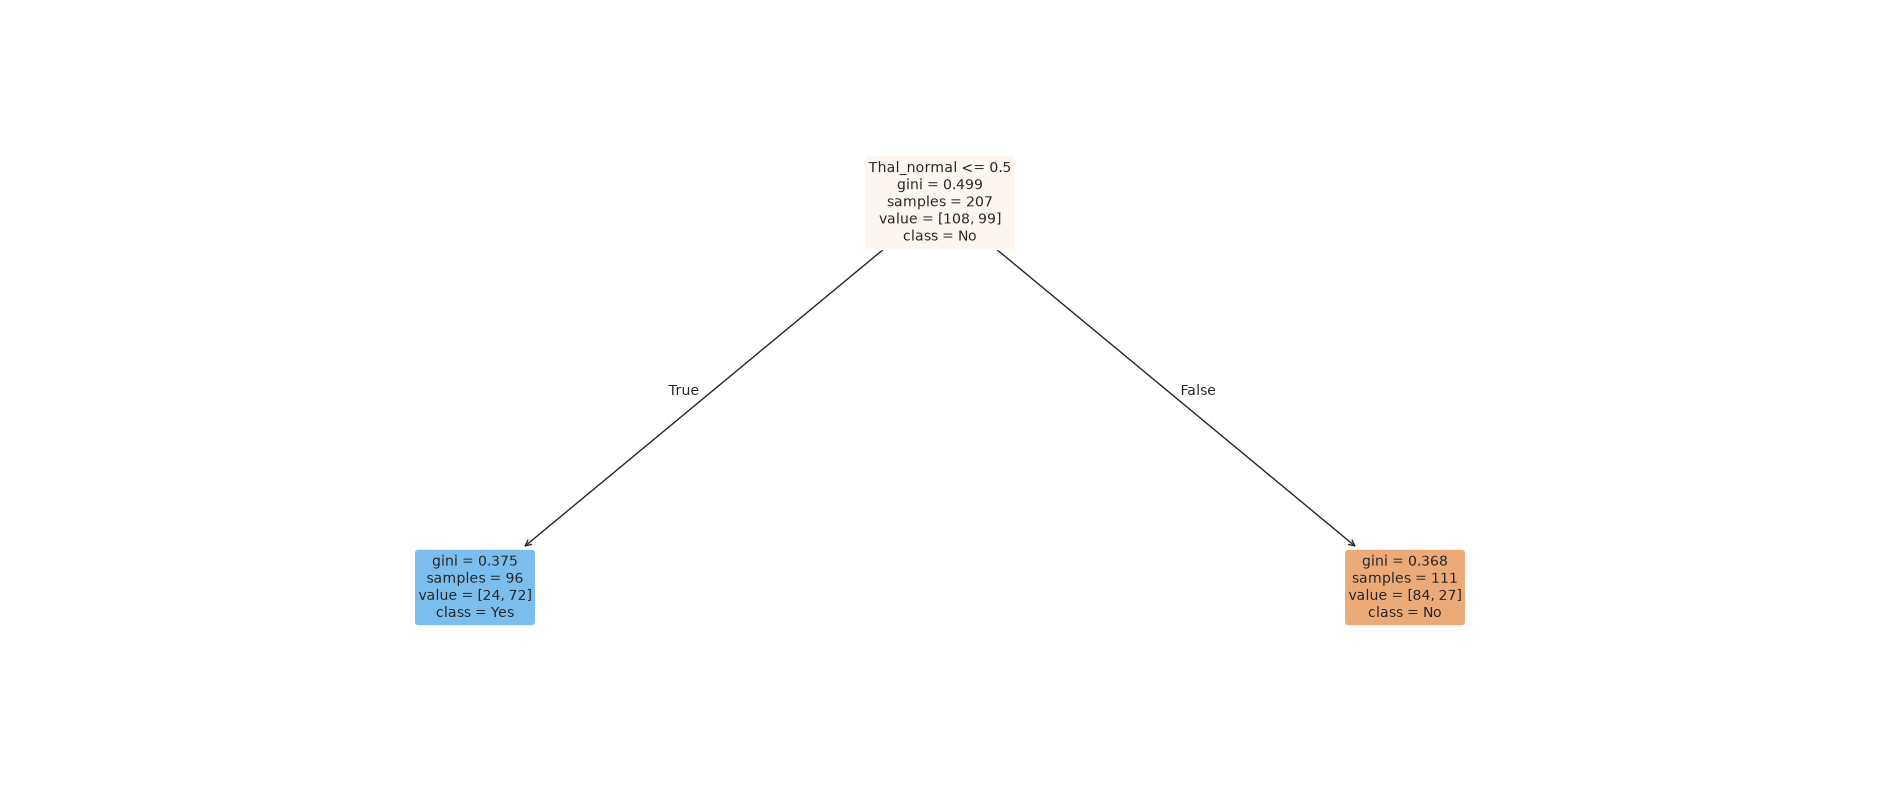

In [35]:
plt.figure(figsize=(24,10))
plot_tree(clf_tree_pruned, feature_names=X.columns, class_names=['No', 'Yes'], filled=True, rounded=True, fontsize=10)
plt.show()